In [1]:
from collections import deque
def run_network_analysis(graph, start_node):
    if start_node not in graph:
        print(f"\nIntersection {start_node} does not exist in the network.")
        return

    bfs_order = []
    bfs_visited = set()
    queue = deque([start_node])
    bfs_visited.add(start_node)

    while queue:
        current = queue.popleft()
        bfs_order.append(current)
        for neighbor in graph[current]:
            if neighbor not in bfs_visited:
                bfs_visited.add(neighbor)
                queue.append(neighbor)

    dfs_order = []
    dfs_visited = set()
    stack = [start_node]

    while stack:
        current = stack.pop()
        if current not in dfs_visited:
            dfs_visited.add(current)
            dfs_order.append(current)
            for neighbor in reversed(graph[current]):
                if neighbor not in dfs_visited:
                    stack.append(neighbor)

    print(f"\n--- Results for Starting Intersection: {start_node} ---")
    print(f"BFS Traversal Order: {' -> '.join(bfs_order)}")
    print(f"DFS Traversal Order: {' -> '.join(dfs_order)}")
    print(f"Reachable Intersections ({len(bfs_order)} total): {', '.join(bfs_order)}")

def main():
    user_choice = input("Do you want to enter a custom transportation network? (yes/no): ").strip().lower()
    
    if user_choice == "yes":
        graph = {}
        num_intersections = int(input("Enter the total number of intersections: "))
        for _ in range(num_intersections):
            node = input("Enter intersection name: ").strip()
            neighbors = input(f"Enter connected intersections for {node} (separated by commas): ")
            graph[node] = [n.strip() for n in neighbors.split(",") if n.strip()]
        start_node = input("Enter the starting intersection to inspect: ").strip()
        run_network_analysis(graph, start_node)
        
    else:
        print("\nRunning analysis with default example transportation network...")
        example_graph = {
            "Main_St_&_1st_Ave": ["Main_St_&_2nd_Ave", "Broadway_&_1st_Ave"],
            "Main_St_&_2nd_Ave": ["Main_St_&_1st_Ave", "Broadway_&_2nd_Ave", "Oak_Rd"],
            "Broadway_&_1st_Ave": ["Main_St_&_1st_Ave", "Broadway_&_2nd_Ave"],
            "Broadway_&_2nd_Ave": ["Main_St_&_2nd_Ave", "Broadway_&_1st_Ave", "Expressway_Exit"],
            "Oak_Rd": ["Main_St_&_2nd_Ave"],
            "Expressway_Exit": ["Broadway_&_2nd_Ave"]
        }
        default_start = "Main_St_&_1st_Ave"
        run_network_analysis(example_graph, default_start)

if __name__ == "__main__":
    main()

Do you want to enter a custom transportation network? (yes/no):  no



Running analysis with default example transportation network...

--- Results for Starting Intersection: Main_St_&_1st_Ave ---
BFS Traversal Order: Main_St_&_1st_Ave -> Main_St_&_2nd_Ave -> Broadway_&_1st_Ave -> Broadway_&_2nd_Ave -> Oak_Rd -> Expressway_Exit
DFS Traversal Order: Main_St_&_1st_Ave -> Main_St_&_2nd_Ave -> Broadway_&_2nd_Ave -> Broadway_&_1st_Ave -> Expressway_Exit -> Oak_Rd
Reachable Intersections (6 total): Main_St_&_1st_Ave, Main_St_&_2nd_Ave, Broadway_&_1st_Ave, Broadway_&_2nd_Ave, Oak_Rd, Expressway_Exit


Choose data mode:
1. Use pre-loaded Example Transportation Network
2. Enter Custom Network Info


Enter choice (1 or 2):  1



Running analysis with default example transportation network...

--- Results for Starting Intersection: Main_St_&_1st_Ave ---
BFS Traversal Order: Main_St_&_1st_Ave -> Main_St_&_2nd_Ave -> Broadway_&_1st_Ave -> Broadway_&_2nd_Ave -> Oak_Rd -> Expressway_Exit
DFS Traversal Order: Main_St_&_1st_Ave -> Main_St_&_2nd_Ave -> Broadway_&_2nd_Ave -> Broadway_&_1st_Ave -> Expressway_Exit -> Oak_Rd
Reachable Intersections (6 total): Main_St_&_1st_Ave, Main_St_&_2nd_Ave, Broadway_&_1st_Ave, Broadway_&_2nd_Ave, Oak_Rd, Expressway_Exit


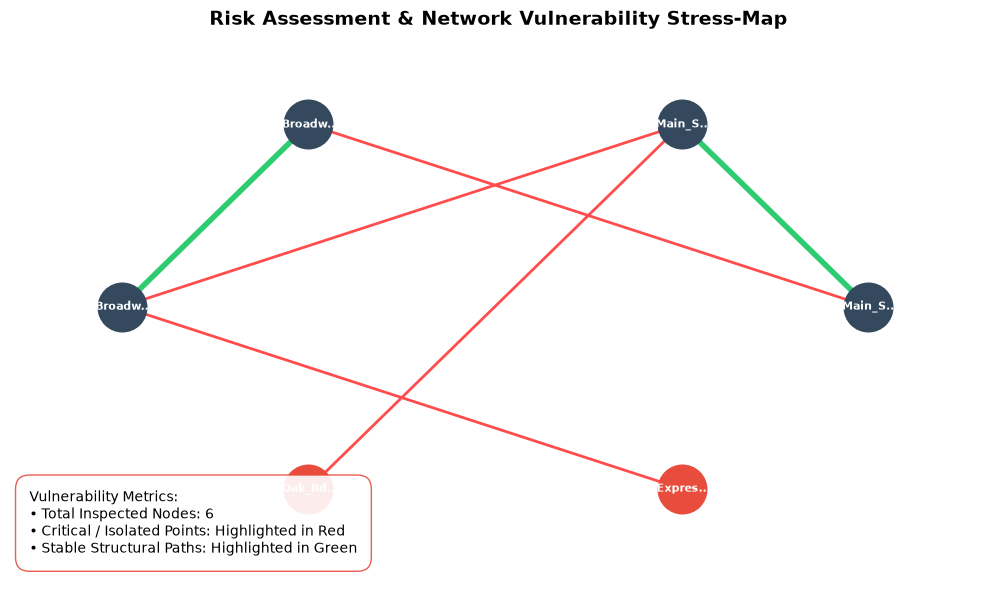

In [2]:
from collections import deque
import matplotlib.pyplot as plt
import math

def run_network_analysis(graph, start_node):
    if start_node not in graph:
        print(f"\nIntersection {start_node} does not exist in the network.")
        return

    bfs_order = []
    bfs_visited = set()
    queue = deque([start_node])
    bfs_visited.add(start_node)

    while queue:
        current = queue.popleft()
        bfs_order.append(current)
        for neighbor in graph[current]:
            if neighbor not in bfs_visited:
                bfs_visited.add(neighbor)
                queue.append(neighbor)

    dfs_order = []
    dfs_visited = set()
    stack = [start_node]

    while stack:
        current = stack.pop()
        if current not in dfs_visited:
            dfs_visited.add(current)
            dfs_order.append(current)
            for neighbor in reversed(graph[current]):
                if neighbor not in dfs_visited:
                    stack.append(neighbor)

    print(f"\n--- Results for Starting Intersection: {start_node} ---")
    print(f"BFS Traversal Order: {' -> '.join(bfs_order)}")
    print(f"DFS Traversal Order: {' -> '.join(dfs_order)}")
    print(f"Reachable Intersections ({len(bfs_order)} total): {', '.join(bfs_order)}")
    
    visualize_risk_vulnerability(graph, bfs_order)

def visualize_risk_vulnerability(graph, traversal_order):
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.set_title(" Risk Assessment & Network Vulnerability Stress-Map", fontsize=14, fontweight='bold')
    
    nodes = list(graph.keys())
    num_nodes = len(nodes)
    pos = {}
    for idx, node in enumerate(nodes):
        angle = 2 * math.pi * idx / num_nodes
        pos[node] = (math.cos(angle), math.sin(angle))
        
    seen_edges = set()
    for u in graph:
        for v in graph[u]:
            if u not in pos or v not in pos:
                continue
            edge_key = tuple(sorted((u, v)))
            if edge_key in seen_edges:
                continue
            seen_edges.add(edge_key)
            
            x1, y1 = pos[u]
            x2, y2 = pos[v]
            
            is_on_traversal = False
            if traversal_order:
                for i in range(len(traversal_order) - 1):
                    if (traversal_order[i] == u and traversal_order[i+1] == v) or (traversal_order[i] == v and traversal_order[i+1] == u):
                        is_on_traversal = True
                        break
                        
            if is_on_traversal:
                ecolor = '#2ecc71'
                ewidth = 4.0
            else:
                ecolor = '#ff4d4d'
                ewidth = 2.0
                
            ax.plot([x1, x2], [y1, y2], color=ecolor, lw=ewidth)
            
    for node, (x, y) in pos.items():
        ncolor = '#e74c3c' if len(graph[node]) <= 1 else '#34495e'
        ax.plot(x, y, marker='o', markersize=35, color=ncolor, linestyle='None')
        ax.text(x, y, str(node)[:6] + "..", color='white', ha='center', va='center', fontweight='bold', fontsize=8)
        
    metrics_text = f"Vulnerability Metrics:\n• Total Inspected Nodes: {len(traversal_order)}\n• Critical / Isolated Points: Highlighted in Red\n• Stable Structural Paths: Highlighted in Green"
    ax.text(0.02, 0.05, metrics_text, transform=ax.transAxes,
            bbox=dict(facecolor='white', alpha=0.9, edgecolor='#e74c3c', boxstyle='round,pad=1'))
            
    ax.set_xlim(-1.3, 1.3)
    ax.set_ylim(-1.3, 1.3)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

def main():
    print("Choose data mode:")
    print("1. Use pre-loaded Example Transportation Network")
    print("2. Enter Custom Network Info")
    choice = input("Enter choice (1 or 2): ").strip()
    
    if choice == "2":
        graph = {}
        num_intersections = int(input("Enter the total number of intersections: "))
        for _ in range(num_intersections):
            node = input("Enter intersection name: ").strip()
            neighbors = input(f"Enter connected intersections for {node} (separated by commas): ")
            graph[node] = [n.strip() for n in neighbors.split(",") if n.strip()]
        start_node = input("Enter the starting intersection to inspect: ").strip()
        run_network_analysis(graph, start_node)
        
    else:
        print("\nRunning analysis with default example transportation network...")
        example_graph = {
            "Main_St_&_1st_Ave": ["Main_St_&_2nd_Ave", "Broadway_&_1st_Ave"],
            "Main_St_&_2nd_Ave": ["Main_St_&_1st_Ave", "Broadway_&_2nd_Ave", "Oak_Rd"],
            "Broadway_&_1st_Ave": ["Main_St_&_1st_Ave", "Broadway_&_2nd_Ave"],
            "Broadway_&_2nd_Ave": ["Main_St_&_2nd_Ave", "Broadway_&_1st_Ave", "Expressway_Exit"],
            "Oak_Rd": ["Main_St_&_2nd_Ave"],
            "Expressway_Exit": ["Broadway_&_2nd_Ave"]
        }
        default_start = "Main_St_&_1st_Ave"
        run_network_analysis(example_graph, default_start)

if __name__ == "__main__":
    main()